In [1]:
import warnings
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.preprocessing import StandardScaler
from sklearn.cluster import AgglomerativeClustering, DBSCAN, SpectralClustering
from sklearn.mixture import GaussianMixture
from sklearn.metrics import silhouette_score, rand_score, adjusted_rand_score, normalized_mutual_info_score
from scipy.cluster.hierarchy import dendrogram, linkage

sns.set_theme(style="whitegrid", context="notebook")
plt.rcParams["figure.dpi"] = 110

# Membaca dataset penguins.csv
df = pd.read_csv("penguins.csv")

print("Shape dataset:", df.shape)
display(df.head())

Shape dataset: (344, 8)


,species,island,bill_length_mm,bill_depth_mm,flipper_length_mm,body_mass_g,sex,year
0,Adelie,Torgersen,39.1,18.7,181.0,3750.0,male,2007
1,Adelie,Torgersen,39.5,17.4,186.0,3800.0,female,2007
2,Adelie,Torgersen,40.3,18.0,195.0,3250.0,female,2007
3,Adelie,Torgersen,NaN,NaN,NaN,NaN,NaN,2007
4,Adelie,Torgersen,36.7,19.3,193.0,3450.0,female,2007


In [2]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 344 entries, 0 to 343
Data columns (total 8 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   species            344 non-null    str    
 1   island             344 non-null    str    
 2   bill_length_mm     342 non-null    float64
 3   bill_depth_mm      342 non-null    float64
 4   flipper_length_mm  342 non-null    float64
 5   body_mass_g        342 non-null    float64
 6   sex                333 non-null    str    
 7   year               344 non-null    int64  
dtypes: float64(4), int64(1), str(3)
memory usage: 21.6 KB


In [3]:
num_cols = ["bill_length_mm", "bill_depth_mm", "flipper_length_mm", "body_mass_g"]

print("Jumlah nilai kosong per kolom:")
print(df.isna().sum())

rows_before = len(df)
df_clean = df.dropna(subset=num_cols + ["species"]).reset_index(drop=True)
rows_after = len(df_clean)

print(f"\nJumlah baris sebelum pembersihan : {rows_before}")
print(f"Jumlah baris sesudah pembersihan : {rows_after}")
print(f"Jumlah baris yang dihapus        : {rows_before - rows_after}")

print("\nJumlah data per spesies setelah pembersihan:")
print(df_clean["species"].value_counts())

Jumlah nilai kosong per kolom:
species               0
island                0
bill_length_mm        2
bill_depth_mm         2
flipper_length_mm     2
body_mass_g           2
sex                  11
year                  0
dtype: int64

Jumlah baris sebelum pembersihan : 344
Jumlah baris sesudah pembersihan : 342
Jumlah baris yang dihapus        : 2

Jumlah data per spesies setelah pembersihan:
species
Adelie       151
Gentoo       123
Chinstrap     68
Name: count, dtype: int64


In [4]:
print("Statistik deskriptif kolom numerik:")
display(df_clean[num_cols].describe().T)

Statistik deskriptif kolom numerik:


,count,mean,std,min,25%,50%,75%,max
bill_length_mm,342.0,43.921930,5.459584,32.1,39.225,44.45,48.5,59.6
bill_depth_mm,342.0,17.151170,1.974793,13.1,15.600,17.30,18.7,21.5
flipper_length_mm,342.0,200.915205,14.061714,172.0,190.000,197.00,213.0,231.0
body_mass_g,342.0,4201.754386,801.954536,2700.0,3550.000,4050.00,4750.0,6300.0


**Pengamatan Skala Antar Kolom:**
Dari tabel statistik deskriptif di atas, terlihat perbedaan skala yang sangat jauh antar fitur numerik:
- `bill_length_mm` dan `bill_depth_mm` berada pada rentang puluhan milimeter (sekitar 13–60 mm).
- `flipper_length_mm` berada pada rentang ratusan milimeter (172–231 mm).
- `body_mass_g` berada pada rentang ribuan gram (2700–6300 g).

Karena algoritma clustering berbasis jarak (seperti Agglomerative, DBSCAN, dan Spectral Clustering) maupun kepadatan/kovariansi (GMM) sangat sensitif terhadap skala fitur, standardisasi wajib dilakukan sebelum pemodelan.

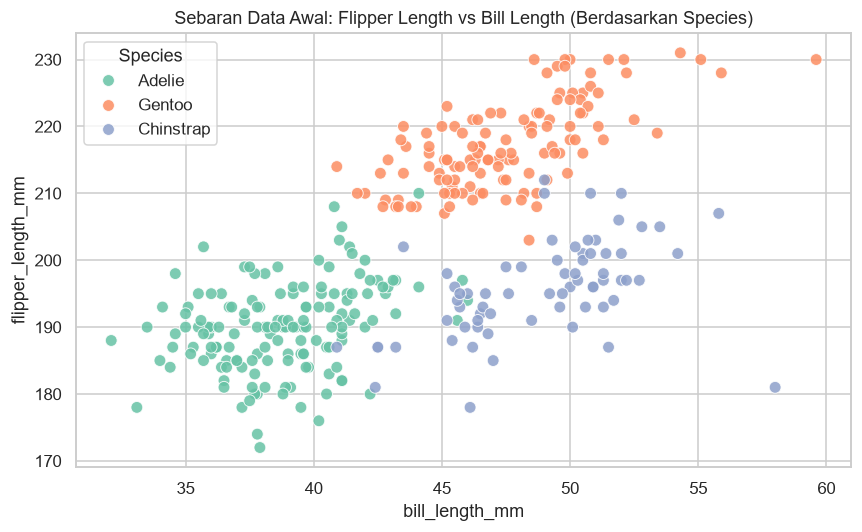

In [5]:
plt.figure(figsize=(8, 5))
sns.scatterplot(
    data=df_clean,
    x="bill_length_mm",
    y="flipper_length_mm",
    hue="species",
    palette="Set2",
    s=60,
    alpha=0.85,
)
plt.title("Sebaran Data Awal: Flipper Length vs Bill Length (Berdasarkan Species)")
plt.xlabel("bill_length_mm")
plt.ylabel("flipper_length_mm")
plt.legend(title="Species")
plt.tight_layout()
plt.show()

In [6]:
X = df_clean[num_cols].copy()
y = df_clean["species"].copy()

scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)

X_scaled_df = pd.DataFrame(X_scaled, columns=num_cols)
print("Statistik setelah standardisasi (z-score):")
display(X_scaled_df.describe().T[["mean", "std", "min", "max"]].round(4))

Statistik setelah standardisasi (z-score):


,mean,std,min,max
bill_length_mm,0.0,1.0015,-2.1685,2.8759
bill_depth_mm,0.0,1.0015,-2.0544,2.2054
flipper_length_mm,-0.0,1.0015,-2.0593,2.1426
body_mass_g,0.0,1.0015,-1.8754,2.6202


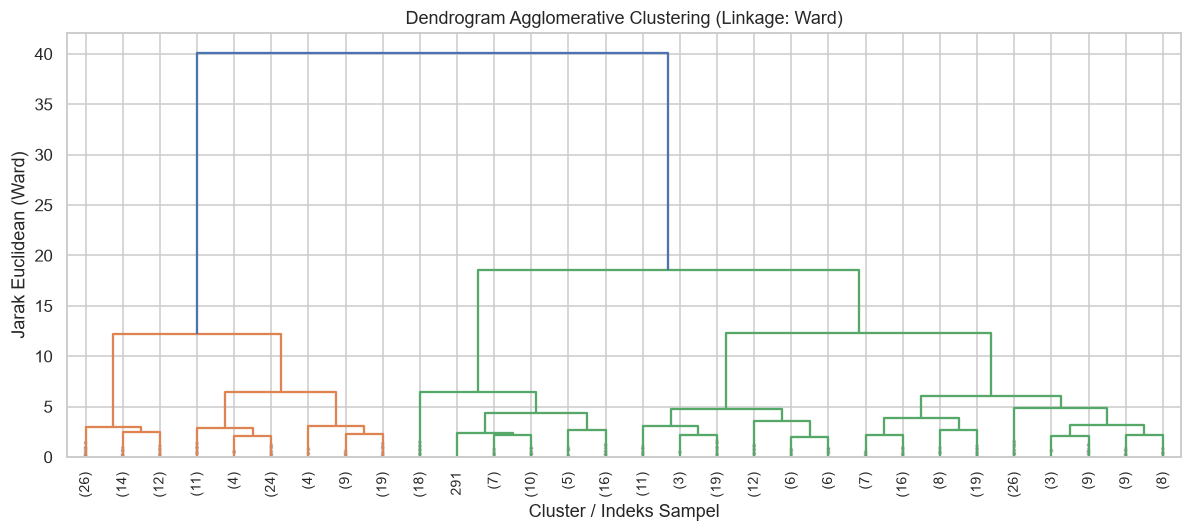

Distribusi kluster Agglomerative: {0: 162, 1: 123, 2: 57}


In [7]:
# Dendrogram menggunakan scipy dengan Ward linkage
Z = linkage(X_scaled, method="ward")

plt.figure(figsize=(11, 5))
dendrogram(Z, truncate_mode="lastp", p=30, leaf_rotation=90, leaf_font_size=9, show_contracted=True)
plt.title("Dendrogram Agglomerative Clustering (Linkage: Ward)")
plt.xlabel("Cluster / Indeks Sampel")
plt.ylabel("Jarak Euclidean (Ward)")
plt.tight_layout()
plt.show()

# Penerapan Agglomerative Clustering dengan 3 kluster dan Ward linkage
agg = AgglomerativeClustering(n_clusters=3, linkage="ward")
labels_agg = agg.fit_predict(X_scaled)
print("Distribusi kluster Agglomerative:", pd.Series(labels_agg).value_counts().sort_index().to_dict())

In [8]:
eps_values = [0.3, 0.4, 0.5, 0.6, 0.7, 0.8, 1.0]
dbscan_experiments = []

for eps in eps_values:
    db = DBSCAN(eps=eps, min_samples=5)
    lbl = db.fit_predict(X_scaled)
    n_clusters = len(set(lbl) - {-1})
    n_noise = int(np.sum(lbl == -1))
    dbscan_experiments.append({
        "eps": eps,
        "min_samples": 5,
        "jumlah_kluster": n_clusters,
        "jumlah_noise": n_noise,
        "persen_noise (%)": round(100 * n_noise / len(lbl), 2),
    })

dbscan_exp_df = pd.DataFrame(dbscan_experiments)
print("Hasil eksperimen berbagai nilai eps pada DBSCAN (MinPts=5):")
display(dbscan_exp_df)

# Model awal sesuai ketentuan: eps=0.5, MinPts=5
dbscan_05 = DBSCAN(eps=0.5, min_samples=5)
labels_db_05 = dbscan_05.fit_predict(X_scaled)

# Model DBSCAN dengan eps=0.6 sebagai pembanding yang lebih sedikit noise
dbscan_06 = DBSCAN(eps=0.6, min_samples=5)
labels_db_06 = dbscan_06.fit_predict(X_scaled)

# Gunakan eps=0.5 sebagai model utama DBSCAN sesuai titik awal instruksi
labels_db = labels_db_05
print(f"DBSCAN (eps=0.5, MinPts=5) -> Kluster: {len(set(labels_db) - {-1})}, Noise: {np.sum(labels_db == -1)}")

Hasil eksperimen berbagai nilai eps pada DBSCAN (MinPts=5):


,eps,min_samples,jumlah_kluster,jumlah_noise,persen_noise (%)
0,0.3,5,4,317,92.69
1,0.4,5,10,171,50.00
2,0.5,5,4,69,20.18
3,0.6,5,2,33,9.65
4,0.7,5,2,16,4.68
5,0.8,5,2,5,1.46
6,1.0,5,2,1,0.29


DBSCAN (eps=0.5, MinPts=5) -> Kluster: 4, Noise: 69


In [9]:
# GMM (3 komponen)
gmm = GaussianMixture(n_components=3, random_state=42)
labels_gmm = gmm.fit_predict(X_scaled)
print("Distribusi kluster GMM:", pd.Series(labels_gmm).value_counts().sort_index().to_dict())

# Spectral Clustering (3 kluster)
spectral = SpectralClustering(n_clusters=3, affinity="nearest_neighbors", random_state=42)
labels_spec = spectral.fit_predict(X_scaled)
print("Distribusi kluster Spectral:", pd.Series(labels_spec).value_counts().sort_index().to_dict())

Distribusi kluster GMM: {0: 67, 1: 123, 2: 152}
Distribusi kluster Spectral: {0: 162, 1: 123, 2: 57}


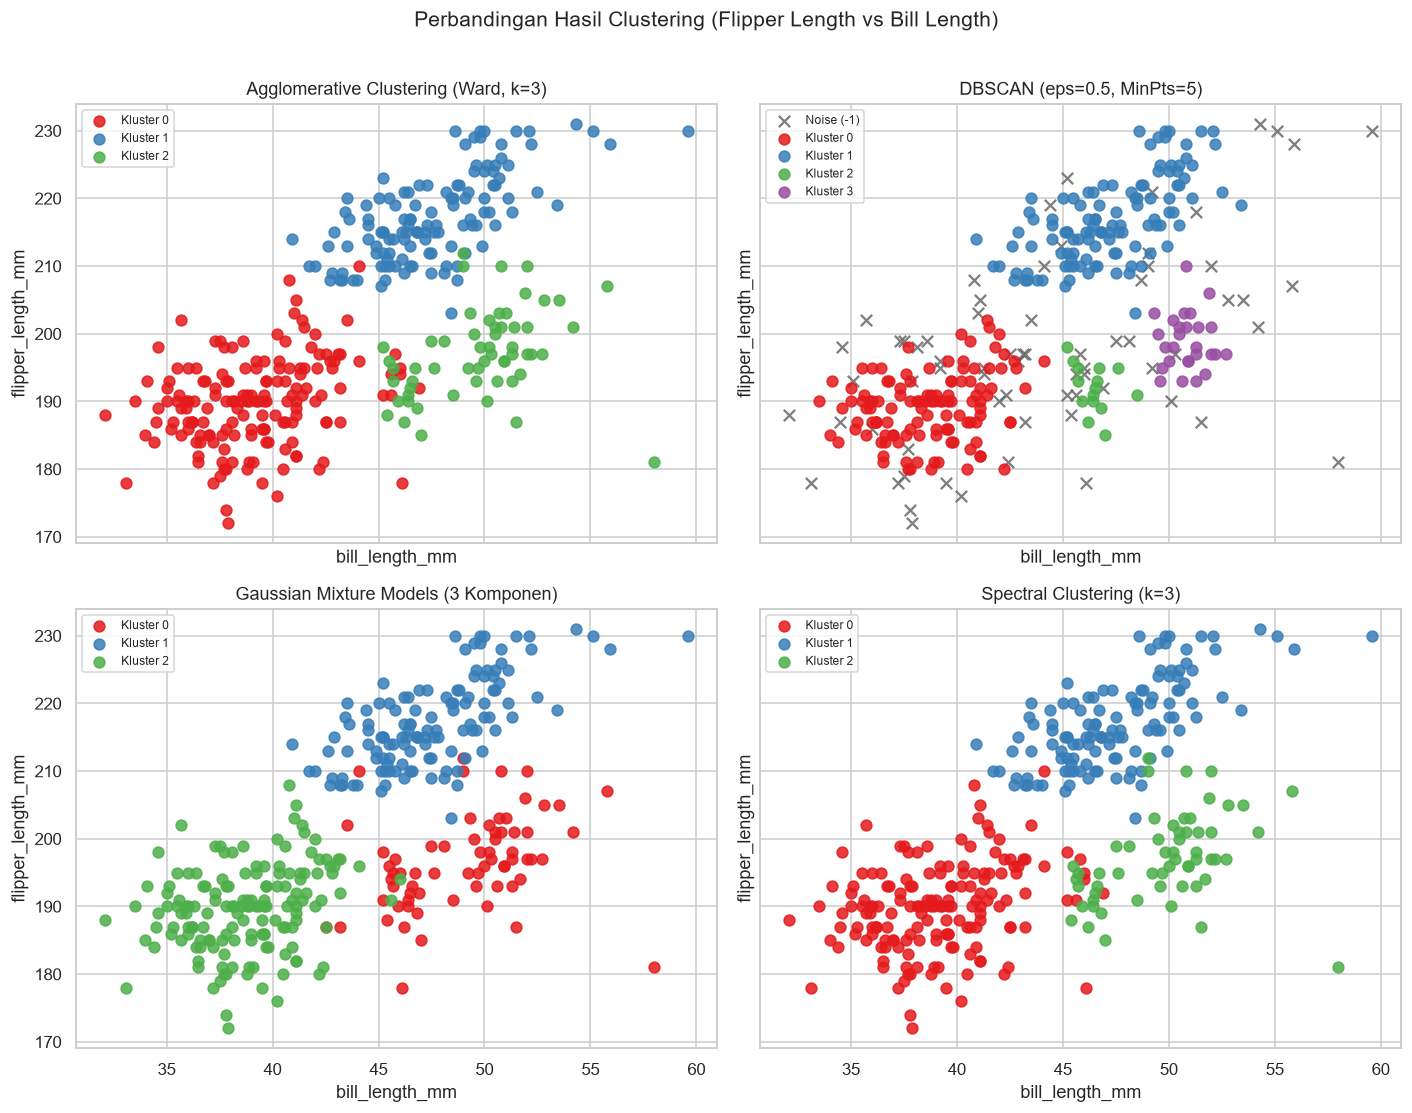

In [10]:
fig, axes = plt.subplots(2, 2, figsize=(13, 10), sharex=True, sharey=True)

plot_configs = [
    ("Agglomerative Clustering (Ward, k=3)", labels_agg, axes[0, 0]),
    ("DBSCAN (eps=0.5, MinPts=5)", labels_db, axes[0, 1]),
    ("Gaussian Mixture Models (3 Komponen)", labels_gmm, axes[1, 0]),
    ("Spectral Clustering (k=3)", labels_spec, axes[1, 1]),
]

palette = sns.color_palette("Set1", n_colors=10)

for title, lbls, ax in plot_configs:
    unique_lbls = sorted(set(lbls))
    for k in unique_lbls:
        mask = (lbls == k)
        if k == -1:
            ax.scatter(
                df_clean.loc[mask, "bill_length_mm"],
                df_clean.loc[mask, "flipper_length_mm"],
                c="dimgray",
                marker="x",
                s=55,
                label="Noise (-1)",
                alpha=0.85,
            )
        else:
            ax.scatter(
                df_clean.loc[mask, "bill_length_mm"],
                df_clean.loc[mask, "flipper_length_mm"],
                color=palette[k % len(palette)],
                s=50,
                label=f"Kluster {k}",
                alpha=0.85,
            )
    ax.set_title(title)
    ax.set_xlabel("bill_length_mm")
    ax.set_ylabel("flipper_length_mm")
    ax.legend(fontsize=8, loc="best")

plt.suptitle("Perbandingan Hasil Clustering (Flipper Length vs Bill Length)", fontsize=14, y=1.01)
plt.tight_layout()
plt.show()

In [11]:
def evaluate_clustering(X_data, y_true, labels, is_dbscan=False):
    n_noise = int(np.sum(labels == -1)) if is_dbscan else 0
    if is_dbscan:
        mask = labels != -1
        X_eval = X_data[mask]
        lbl_eval = labels[mask]
        n_clusters = len(set(lbl_eval))
        sil = silhouette_score(X_eval, lbl_eval) if n_clusters >= 2 and len(lbl_eval) > n_clusters else np.nan
    else:
        n_clusters = len(set(labels))
        sil = silhouette_score(X_data, labels) if n_clusters >= 2 else np.nan

    ri = rand_score(y_true, labels)
    ari = adjusted_rand_score(y_true, labels)
    nmi = normalized_mutual_info_score(y_true, labels)
    return {
        "Kluster": n_clusters,
        "Noise Dibuang": n_noise,
        "Silhouette Score": round(float(sil), 4) if not np.isnan(sil) else np.nan,
        "Rand Index": round(float(ri), 4),
        "Adjusted Rand Index": round(float(ari), 4),
        "NMI": round(float(nmi), 4),
    }

full_results = [
    {"Algoritma": "Agglomerative (Ward)", **evaluate_clustering(X_scaled, y, labels_agg)},
    {"Algoritma": "DBSCAN (eps=0.5, MinPts=5)", **evaluate_clustering(X_scaled, y, labels_db, is_dbscan=True)},
    {"Algoritma": "GMM (3 komponen)", **evaluate_clustering(X_scaled, y, labels_gmm)},
    {"Algoritma": "Spectral Clustering (k=3)", **evaluate_clustering(X_scaled, y, labels_spec)},
]

full_eval_df = pd.DataFrame(full_results)
print("Hasil Evaluasi pada Data Penuh (100%):")
display(full_eval_df)

Hasil Evaluasi pada Data Penuh (100%):


,Algoritma,Kluster,Noise Dibuang,Silhouette Score,Rand Index,Adjusted Rand Index,NMI
0,Agglomerative (Ward),3,0,0.4541,0.9608,0.9159,0.9007
1,"DBSCAN (eps=0.5, MinPts=5)",4,69,0.4235,0.8525,0.6632,0.6631
2,GMM (3 komponen),3,0,0.4545,0.9817,0.9603,0.9349
3,Spectral Clustering (k=3),3,0,0.4550,0.9608,0.9159,0.9007


In [12]:
# Uji Kestabilan: 90% data diambil acak sebanyak 3 kali
stability_rows = []
seeds = [1, 2, 3]

for run_idx, seed in enumerate(seeds, start=1):
    rng = np.random.default_rng(seed)
    sample_idx = np.sort(rng.choice(len(X_scaled), size=int(0.9 * len(X_scaled)), replace=False))
    X_sub = X_scaled[sample_idx]
    y_sub = y.iloc[sample_idx].reset_index(drop=True)

    lbl_agg_sub = AgglomerativeClustering(n_clusters=3, linkage="ward").fit_predict(X_sub)
    lbl_db_sub = DBSCAN(eps=0.5, min_samples=5).fit_predict(X_sub)
    lbl_gmm_sub = GaussianMixture(n_components=3, random_state=42).fit_predict(X_sub)
    lbl_spec_sub = SpectralClustering(n_clusters=3, affinity="nearest_neighbors", random_state=42).fit_predict(X_sub)

    models_sub = [
        ("Agglomerative (Ward)", lbl_agg_sub, False),
        ("DBSCAN (eps=0.5, MinPts=5)", lbl_db_sub, True),
        ("GMM (3 komponen)", lbl_gmm_sub, False),
        ("Spectral Clustering (k=3)", lbl_spec_sub, False),
    ]

    for name, lbl_sub, is_db in models_sub:
        metrics = evaluate_clustering(X_sub, y_sub, lbl_sub, is_dbscan=is_db)
        stability_rows.append({"Run (90% data)": f"Run {run_idx} (seed={seed})", "Algoritma": name, **metrics})

stability_df = pd.DataFrame(stability_rows)
print("Hasil Uji Kestabilan (3x Sampling 90% Data):")
display(stability_df)

Hasil Uji Kestabilan (3x Sampling 90% Data):


,Run (90% data),Algoritma,Kluster,Noise Dibuang,Silhouette Score,Rand Index,Adjusted Rand Index,NMI
0,Run 1 (seed=1),Agglomerative (Ward),3,0,0.4547,0.9653,0.9255,0.9079
1,Run 1 (seed=1),"DBSCAN (eps=0.5, MinPts=5)",4,70,0.4501,0.8481,0.6516,0.6746
2,Run 1 (seed=1),GMM (3 komponen),3,0,0.4494,0.9803,0.9573,0.9298
3,Run 1 (seed=1),Spectral Clustering (k=3),3,0,0.4645,0.9122,0.8152,0.8231
4,Run 2 (seed=2),Agglomerative (Ward),3,0,0.4492,0.9717,0.9394,0.9219
5,Run 2 (seed=2),"DBSCAN (eps=0.5, MinPts=5)",4,70,0.4206,0.8328,0.6195,0.6319
6,Run 2 (seed=2),GMM (3 komponen),3,0,0.4210,0.9314,0.8504,0.8358
7,Run 2 (seed=2),Spectral Clustering (k=3),3,0,0.4489,0.9602,0.9151,0.8995
8,Run 3 (seed=3),Agglomerative (Ward),3,0,0.4500,0.9712,0.9386,0.9127
9,Run 3 (seed=3),"DBSCAN (eps=0.5, MinPts=5)",4,67,0.4127,0.8395,0.6359,0.6508


In [13]:
# Rangkuman akhir: perbandingan data penuh vs rata-rata & std uji kestabilan 90%
stability_summary = (
    stability_df.groupby("Algoritma", sort=False)[["Silhouette Score", "Rand Index", "NMI", "Noise Dibuang"]]
    .agg(["mean", "std"])
    .round(4)
)
stability_summary.columns = [f"{col} ({stat} 90%)" for col, stat in stability_summary.columns]

final_comparison = full_eval_df.merge(stability_summary, on="Algoritma")
print("Tabel Perbandingan Akhir (Data Penuh vs Uji Kestabilan 90%):")
display(final_comparison)

Tabel Perbandingan Akhir (Data Penuh vs Uji Kestabilan 90%):


,Algoritma,Kluster,Noise Dibuang,Silhouette Score,Rand Index,Adjusted Rand Index,NMI,Silhouette Score (mean 90%),Silhouette Score (std 90%),Rand Index (mean 90%),Rand Index (std 90%),NMI (mean 90%),NMI (std 90%),Noise Dibuang (mean 90%),Noise Dibuang (std 90%)
0,Agglomerative (Ward),3,0,0.4541,0.9608,0.9159,0.9007,0.4513,0.0030,0.9694,0.0036,0.9142,0.0071,0.0,0.0000
1,"DBSCAN (eps=0.5, MinPts=5)",4,69,0.4235,0.8525,0.6632,0.6631,0.4278,0.0197,0.8401,0.0077,0.6524,0.0214,69.0,1.7321
2,GMM (3 komponen),3,0,0.4545,0.9817,0.9603,0.9349,0.4404,0.0168,0.9650,0.0291,0.9018,0.0574,0.0,0.0000
3,Spectral Clustering (k=3),3,0,0.4550,0.9608,0.9159,0.9007,0.4597,0.0094,0.9297,0.0265,0.8513,0.0419,0.0,0.0000


### Ringkasan & Kesimpulan Evaluasi

1. **Agglomerative Clustering (Ward)**, **GMM**, dan **Spectral Clustering** mampu membagi data ke dalam 3 kluster yang sangat selaras dengan label `species` (nilai Rand Index dan NMI tinggi), serta menunjukkan kestabilan yang baik saat diuji ulang pada 90% data acak.
2. **DBSCAN (`eps=0.5, MinPts=5`)** sangat sensitif terhadap kepadatan lokal sehingga menghasilkan cukup banyak titik noise (yang dibuang saat perhitungan Silhouette Score). Pengubahan nilai `eps` pada eksperimen memperlihatkan trade-off langsung antara jumlah kluster yang terbentuk dan banyaknya titik noise.